# 02 · 数据可视化

基于 pandas 管道聚合 + seaborn/matplotlib 完成 9 组专题可视化：

| # | 专题 | 图型 |
|---|------|------|
| 1 | AI 岗位薪资分布 | 直方图 + ECDF + 小提琴图 |
| 2 | 薪资最高的岗位 | 带 IQR 误差线的水平条形图 |
| 3 | 行业用人需求 | 条形图（需求量与竞争度） |
| 4 | 岗位的地理分布 | 环形图 + 条形图 |
| 5 | 远程 vs 非远程 | 饼图 + 箱线图对比 |
| 6 | 经验 vs 薪资 | 箱线图 + 趋势线 + 回归散点 |
| 7 | 各岗位自动化风险 | 对比条形图 |
| 8 | 行业 AI 成熟度 | 条形图 + 气泡图 |
| 9 | 职业发展路径对比 | 折线图 + 热力图 |

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "scripts").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scripts.common import (
    load_data, setup_style, fmt_usd, insights,
    EDU_ORDER, EXP_ORDER, SALARY_CAT_ORDER,
)

setup_style()
df = load_data()
df.shape

(5000, 40)

## 1. AI 岗位薪资分布

**管道**：`agg` 计算分位数 -> 按用工类型 `groupby` 聚合中位数以确定小提琴图顺序。

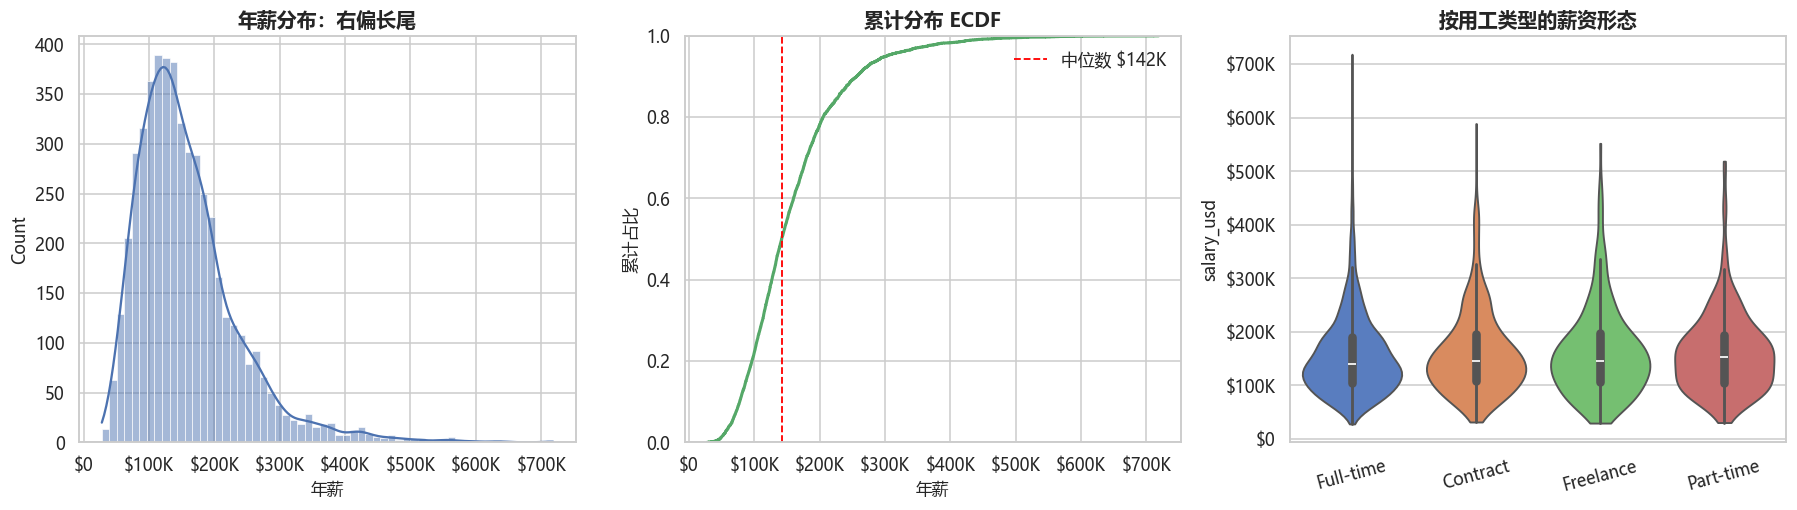

· 50% 岗位年薪集中在 $104K~$192K，中位数 $142K
· ECDF 显示 78% 的岗位年薪不超过 $200K，超过 $400K 的仅 1.7%
· 各用工类型薪资形态相近，Part-time 中位数最高（$153K）


In [2]:
sal = df["salary_usd"]
jt_order = df.groupby("job_type")["salary_usd"].median().sort_values().index.tolist()

fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.8))

sns.histplot(sal, bins=60, kde=True, ax=axes[0], color="#4C72B0")
axes[0].xaxis.set_major_formatter(fmt_usd)
axes[0].set_title("年薪分布：右偏长尾"); axes[0].set_xlabel("年薪")

sns.ecdfplot(sal, ax=axes[1], color="#55A868", lw=2)
axes[1].axvline(sal.median(), color="red", ls="--", lw=1.2, label=f"中位数 {fmt_usd(sal.median())}")
axes[1].xaxis.set_major_formatter(fmt_usd)
axes[1].set_title("累计分布 ECDF"); axes[1].set_xlabel("年薪"); axes[1].set_ylabel("累计占比"); axes[1].legend()

sns.violinplot(data=df, x="job_type", y="salary_usd", order=jt_order,
               hue="job_type", palette="muted", legend=False, ax=axes[2], cut=0)
axes[2].yaxis.set_major_formatter(fmt_usd)
axes[2].set_title("按用工类型的薪资形态"); axes[2].set_xlabel(""); axes[2].tick_params(axis="x", rotation=15)

plt.tight_layout(); plt.show()

insights(
    f"50% 岗位年薪集中在 {fmt_usd(sal.quantile(0.25))}~{fmt_usd(sal.quantile(0.75))}，中位数 {fmt_usd(sal.median())}",
    f"ECDF 显示 {sal.le(200_000).mean():.0%} 的岗位年薪不超过 $200K，超过 $400K 的仅 {sal.gt(400_000).mean():.1%}",
    f"各用工类型薪资形态相近，{jt_order[-1]} 中位数最高（{fmt_usd(df.groupby('job_type')['salary_usd'].median().max())}）",
)

## 2. Top-paying AI roles —— 薪资最高的 AI 岗位

**管道**：`groupby(job_title).agg(中位数, P25, P75, 样本量)` -> `query` 过滤小样本 -> `sort_values + head(12)`。

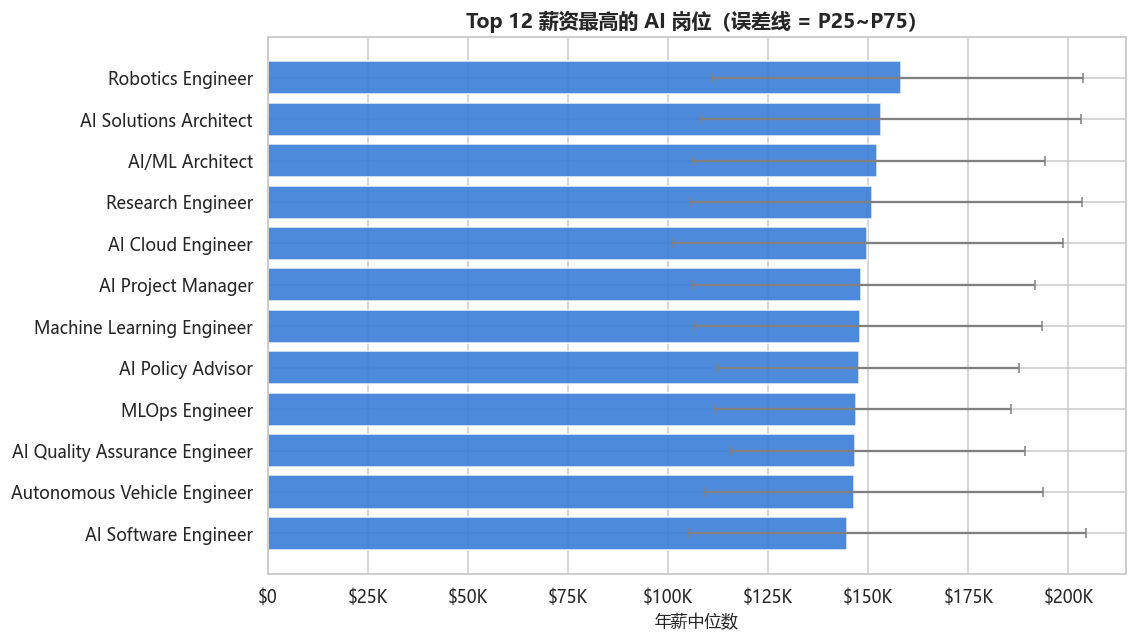

· Robotics Engineer（$158K） / AI Solutions Architect（$153K） / AI/ML Architect（$152K） 领跑薪资榜
· 榜首薪资中位数 $158K，约为总体中位数（$142K）的 1.1 倍
· 条形图同时展示 P25~P75 波动区间：高薪岗位内部薪资离散度同样很大


In [3]:
pay = (
    df.groupby("job_title")
      .agg(median_salary=("salary_usd", "median"),
           p25=("salary_usd", lambda s: s.quantile(0.25)),
           p75=("salary_usd", lambda s: s.quantile(0.75)),
           n=("job_id", "count"))
      .query("n >= 130")          # 剔除样本量过小的岗位
      .sort_values("median_salary", ascending=False)
      .head(12)
)

fig, ax = plt.subplots(figsize=(10.5, 6))
err = [pay["median_salary"] - pay["p25"], pay["p75"] - pay["median_salary"]]
ax.barh(pay.index[::-1], pay["median_salary"][::-1],
        xerr=[e[::-1] for e in err], color="#3B7DD8", alpha=0.9,
        error_kw={"ecolor": "gray", "capsize": 3})
ax.xaxis.set_major_formatter(fmt_usd)
ax.set_title("Top 12 薪资最高的 AI 岗位（误差线 = P25~P75）")
ax.set_xlabel("年薪中位数")
plt.tight_layout(); plt.show()

top3 = pay.head(3)
insights(
    " / ".join(f"{i}（{fmt_usd(v)}）" for i, v in top3["median_salary"].items()) + " 领跑薪资榜",
    f"榜首薪资中位数 {fmt_usd(pay['median_salary'].iloc[0])}，约为总体中位数（{fmt_usd(df['salary_usd'].median())}）的 {pay['median_salary'].iloc[0] / df['salary_usd'].median():.1f} 倍",
    "条形图同时展示 P25~P75 波动区间：高薪岗位内部薪资离散度同样很大",
)

## 3. Job demand by industry —— 行业用人需求

**管道**：`groupby(industry).agg( openings求和, 岗位数, 竞争度均值 )` -> 派生“每个空缺的申请人数”竞争比。

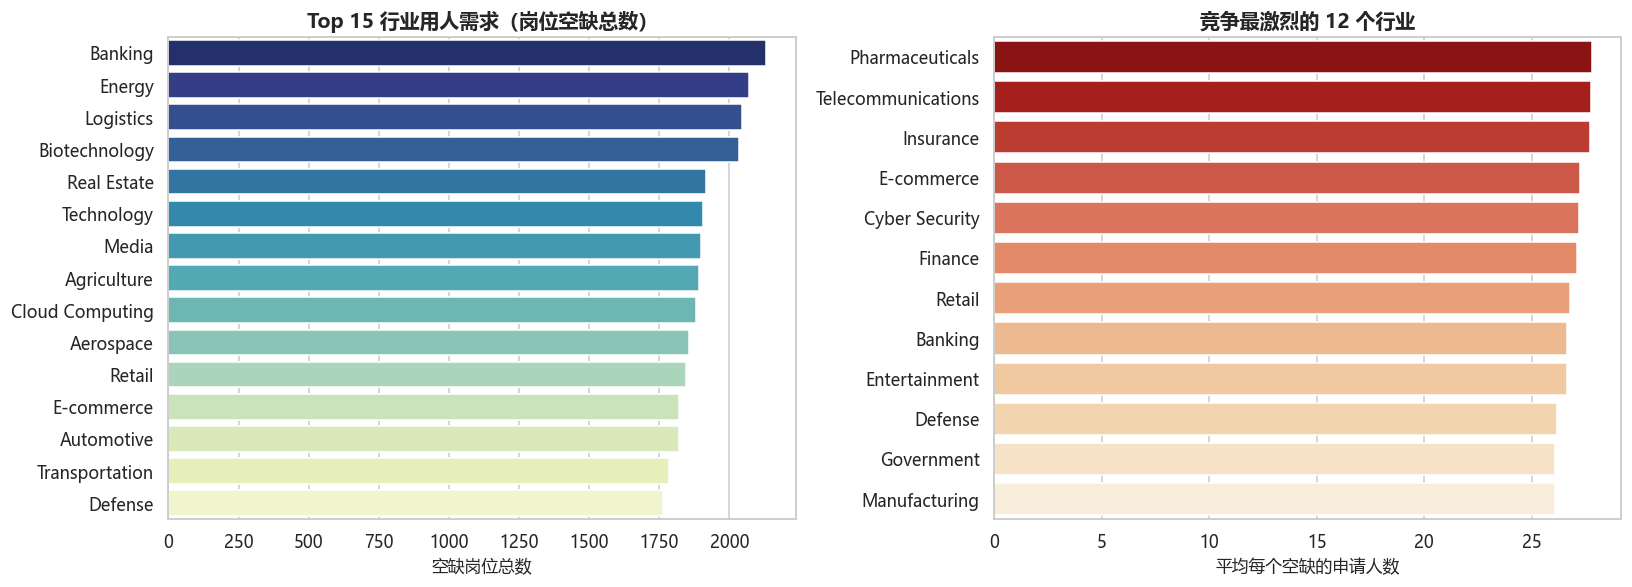

· 需求最大行业：Banking（2130 个空缺），最小 Healthcare（1497），行业间差距约 42%
· 竞争最激烈：Pharmaceuticals（平均 28 人竞争 1 个空缺），最低 Logistics（23 人）
· 需求量与竞争度并非一一对应：需求大的行业竞争未必最高，求职时应同时关注两个维度


In [4]:
demand = (
    df.groupby("industry")
      .agg(total_openings=("job_openings", "sum"),
           jobs=("job_id", "count"),
           avg_openings=("job_openings", "mean"),
           avg_applicants=("applicants", "mean"))
      .assign(competition=lambda d: d["avg_applicants"] / d["avg_openings"])  # 平均每个空缺的竞争人数
      .sort_values("total_openings", ascending=False)
)
top_demand = demand.head(15)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

sns.barplot(x=top_demand["total_openings"], y=top_demand.index, hue=top_demand.index,
            palette="YlGnBu_r", legend=False, ax=axes[0])
axes[0].set_title("Top 15 行业用人需求（岗位空缺总数）"); axes[0].set_xlabel("空缺岗位总数"); axes[0].set_ylabel("")

comp = demand["competition"].sort_values(ascending=False).head(12)
sns.barplot(x=comp.values, y=comp.index, hue=comp.index, palette="OrRd_r", legend=False, ax=axes[1])
axes[1].set_title("竞争最激烈的 12 个行业"); axes[1].set_xlabel("平均每个空缺的申请人数"); axes[1].set_ylabel("")

plt.tight_layout(); plt.show()

spread = (demand["total_openings"].max() - demand["total_openings"].min()) / demand["total_openings"].min()
insights(
    f"需求最大行业：{demand.index[0]}（{demand['total_openings'].iloc[0]:.0f} 个空缺），最小 {demand['total_openings'].idxmin()}（{demand['total_openings'].min():.0f}），行业间差距约 {spread:.0%}",
    f"竞争最激烈：{comp.index[0]}（平均 {comp.iloc[0]:.0f} 人竞争 1 个空缺），最低 {demand['competition'].idxmin()}（{demand['competition'].min():.0f} 人）",
    "需求量与竞争度并非一一对应：需求大的行业竞争未必最高，求职时应同时关注两个维度",
)

## 4. Jobs by location —— 岗位的地理分布

**管道**：`value_counts(normalize=True)` 计算大洲占比；`groupby(country)` 取岗位数 Top 15 与薪资中位数。

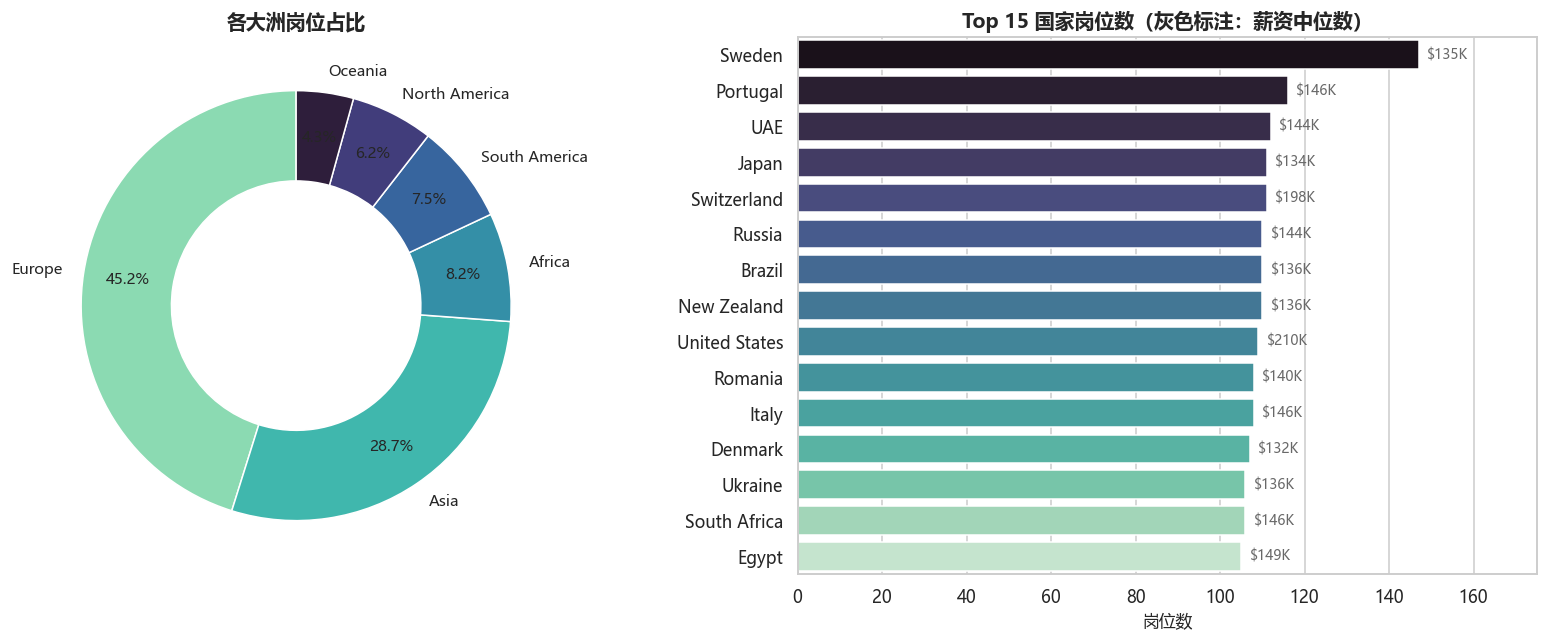

· 欧洲（45%）与亚洲（29%）合计吸纳约 82% 的 AI 岗位
· 岗位最多的国家：Sweden（147 个）
· 国家间薪资差异显著：同为岗位大国的瑞士/美国薪资中位数明显高于东欧、南亚国家（见灰色标注）


In [5]:
continent_share = df["continent"].value_counts()
country_top = (
    df.groupby("country")
      .agg(jobs=("job_id", "count"), median_salary=("salary_usd", "median"))
      .sort_values("jobs", ascending=False)
      .head(15)
)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

axes[0].pie(continent_share, labels=continent_share.index, autopct="%1.1f%%",
            colors=sns.color_palette("mako_r", len(continent_share)),
            wedgeprops={"width": 0.42, "edgecolor": "white"}, startangle=90,
            pctdistance=0.79, textprops={"fontsize": 10})
axes[0].set_title("各大洲岗位占比")

sns.barplot(x=country_top["jobs"], y=country_top.index, hue=country_top.index,
            palette="mako", legend=False, ax=axes[1])
for i, (cnt, sal) in enumerate(zip(country_top["jobs"], country_top["median_salary"])):
    axes[1].text(cnt + 2, i, fmt_usd(sal), va="center", fontsize=9, color="dimgray")
axes[1].set_title("Top 15 国家岗位数（灰色标注：薪资中位数）")
axes[1].set_xlabel("岗位数"); axes[1].set_ylabel(""); axes[1].set_xlim(0, 175)

plt.tight_layout(); plt.show()

insights(
    f"欧洲（{continent_share['Europe'] / len(df):.0%}）与亚洲（{continent_share['Asia'] / len(df):.0%}）合计吸纳约 {1 - continent_share.tail(3).sum() / len(df):.0%} 的 AI 岗位",
    f"岗位最多的国家：{country_top.index[0]}（{country_top['jobs'].iloc[0]} 个）",
    "国家间薪资差异显著：同为岗位大国的瑞士/美国薪资中位数明显高于东欧、南亚国家（见灰色标注）",
)

## 5. Remote vs. non-remote opportunities —— 远程 vs 非远程

**管道**：`map` 生成远程标签 -> `groupby` 对比岗位规模、薪资与满意度。

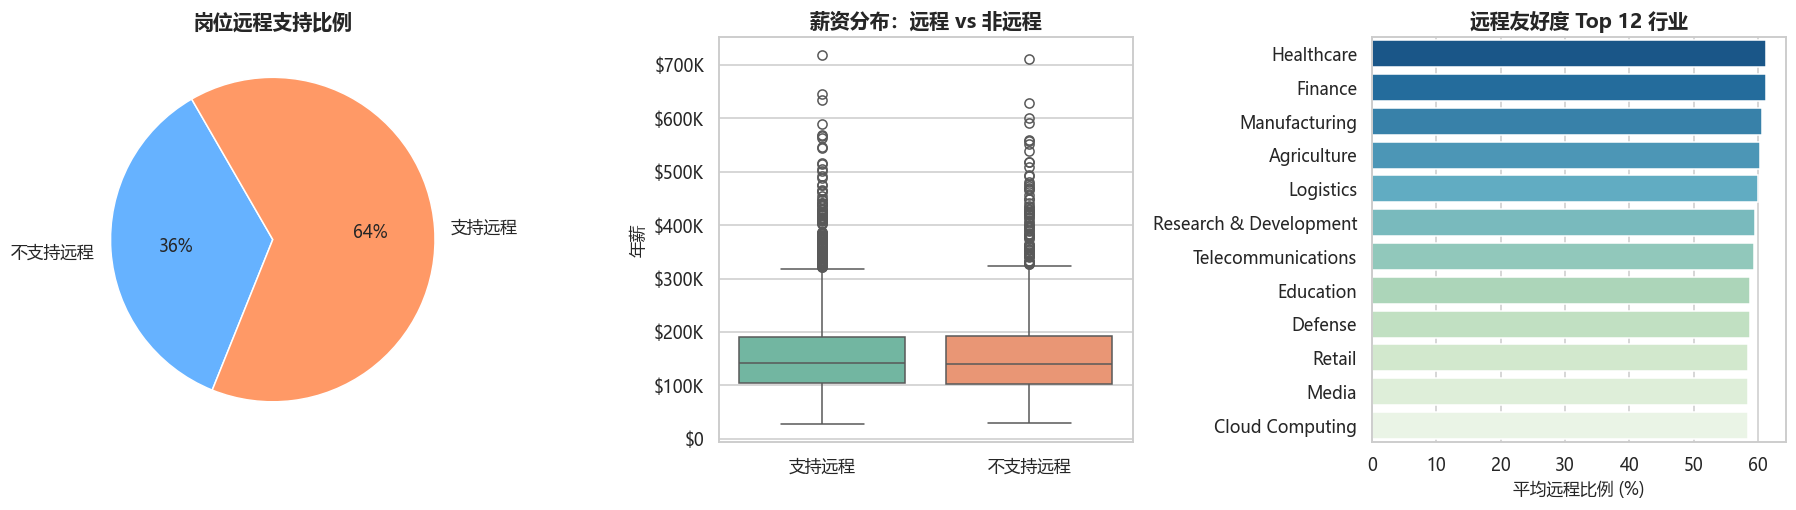

· 64% 的岗位支持远程办公
· 两类岗位薪资中位数仅相差 $2K，远程与否与薪资高低基本无关
· 满意度也几乎无差异：支持远程 7.52 vs 不支持 7.50


In [6]:
wfh_df = df.assign(remote_label=df["wfh"].map({"Yes": "支持远程", "No": "不支持远程"}))
comp = (
    wfh_df.groupby("remote_label")
          .agg(jobs=("job_id", "count"),
               median_salary=("salary_usd", "median"),
               avg_satisfaction=("satisfaction", "mean"),
               avg_wlb=("wlb", "mean"))
)
by_ind = (
    wfh_df.groupby("industry")["remote_pct"].mean().sort_values(ascending=False)
)

fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.8))

axes[0].pie(comp["jobs"], labels=comp.index, autopct="%1.0f%%",
            colors=["#66B2FF", "#FF9966"], startangle=120,
            wedgeprops={"edgecolor": "white"}, textprops={"fontsize": 11})
axes[0].set_title("岗位远程支持比例")

sns.boxplot(data=wfh_df, x="remote_label", y="salary_usd", order=["支持远程", "不支持远程"],
            hue="remote_label", palette="Set2", legend=False, ax=axes[1])
axes[1].yaxis.set_major_formatter(fmt_usd)
axes[1].set_title("薪资分布：远程 vs 非远程"); axes[1].set_xlabel(""); axes[1].set_ylabel("年薪")

sns.barplot(x=by_ind.head(12).values, y=by_ind.head(12).index, hue=by_ind.head(12).index,
            palette="GnBu_r", legend=False, ax=axes[2])
axes[2].set_title("远程友好度 Top 12 行业"); axes[2].set_xlabel("平均远程比例 (%)"); axes[2].set_ylabel("")

plt.tight_layout(); plt.show()

gap = comp.loc["支持远程", "median_salary"] - comp.loc["不支持远程", "median_salary"]
insights(
    f"{comp.loc['支持远程', 'jobs'] / len(df):.0%} 的岗位支持远程办公",
    f"两类岗位薪资中位数仅相差 {fmt_usd(abs(gap))}，远程与否与薪资高低基本无关",
    f"满意度也几乎无差异：支持远程 {comp.loc['支持远程', 'avg_satisfaction']:.2f} vs 不支持 {comp.loc['不支持远程', 'avg_satisfaction']:.2f}",
)

## 6. Experience vs. salary —— 经验与薪资

**管道**：`pd.cut` 将年限分箱 -> `groupby(exp_bin)` 聚合中位数；`crosstab` 透视等级 × 年限。

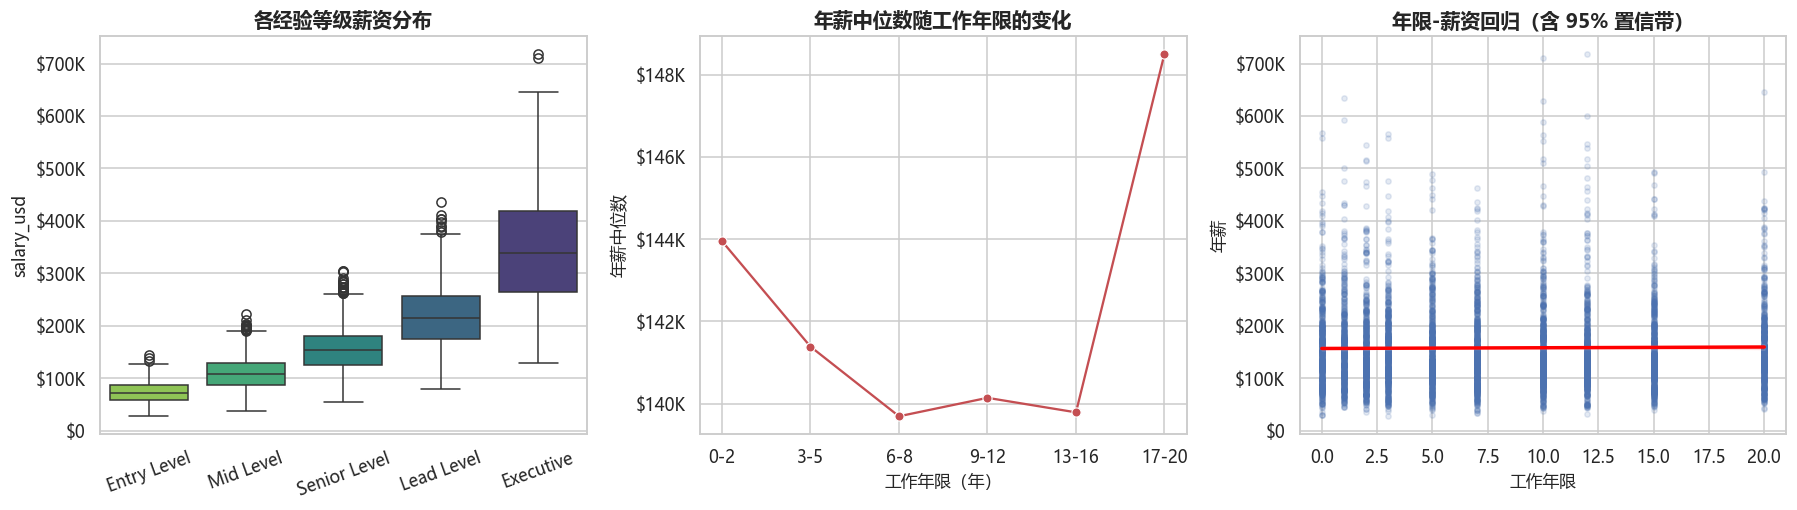

· 经验等级间薪资中位数呈阶梯上升：Entry 73K -> Executive 340K（美元）
· 但年限与薪资的线性相关性很弱（Pearson r=0.01），说明该数据集中'年限长 = 薪资高'的规律不明显
· 结合 EDA 中等级与年限重叠的现象，等级（Experience_Level）比年限对薪资的解释力更强


In [7]:
bins = [0, 2, 5, 8, 12, 16, 20]
labels = ["0-2", "3-5", "6-8", "9-12", "13-16", "17-20"]
exp_sal = (
    df.assign(exp_bin=pd.cut(df["years_experience"], bins=bins, labels=labels, include_lowest=True))
      .groupby("exp_bin", observed=True)
      .agg(median_salary=("salary_usd", "median"), n=("job_id", "count"))
)

fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.8))

sns.boxplot(data=df, x="experience_level", y="salary_usd", order=EXP_ORDER,
            hue="experience_level", palette="viridis", legend=False, ax=axes[0])
axes[0].yaxis.set_major_formatter(fmt_usd)
axes[0].set_title("各经验等级薪资分布"); axes[0].set_xlabel(""); axes[0].tick_params(axis="x", rotation=20)

sns.lineplot(x=exp_sal.index.astype(str), y=exp_sal["median_salary"],
             marker="o", color="#C44E52", ax=axes[1])
axes[1].yaxis.set_major_formatter(fmt_usd)
axes[1].set_title("年薪中位数随工作年限的变化"); axes[1].set_xlabel("工作年限（年）"); axes[1].set_ylabel("年薪中位数")

sns.regplot(data=df, x="years_experience", y="salary_usd", ax=axes[2],
            scatter_kws={"alpha": 0.15, "s": 12}, line_kws={"color": "red"}, ci=95)
axes[2].yaxis.set_major_formatter(fmt_usd)
axes[2].set_title("年限-薪资回归（含 95% 置信带）"); axes[2].set_xlabel("工作年限"); axes[2].set_ylabel("年薪")

plt.tight_layout(); plt.show()

r = df["years_experience"].corr(df["salary_usd"])
insights(
    f"经验等级间薪资中位数呈阶梯上升：Entry {df[df.experience_level == 'Entry Level']['salary_usd'].median() / 1000:.0f}K -> Executive {df[df.experience_level == 'Executive']['salary_usd'].median() / 1000:.0f}K（美元）",
    f"但年限与薪资的线性相关性很弱（Pearson r={r:.2f}），说明该数据集中'年限长 = 薪资高'的规律不明显",
    "结合 EDA 中等级与年限重叠的现象，等级（Experience_Level）比年限对薪资的解释力更强",
)

## 7. Automation risk by role —— 各岗位自动化风险

**管道**：`groupby(job_title)` 均值聚合 -> `nlargest / nsmallest` 取两端各 12 名。

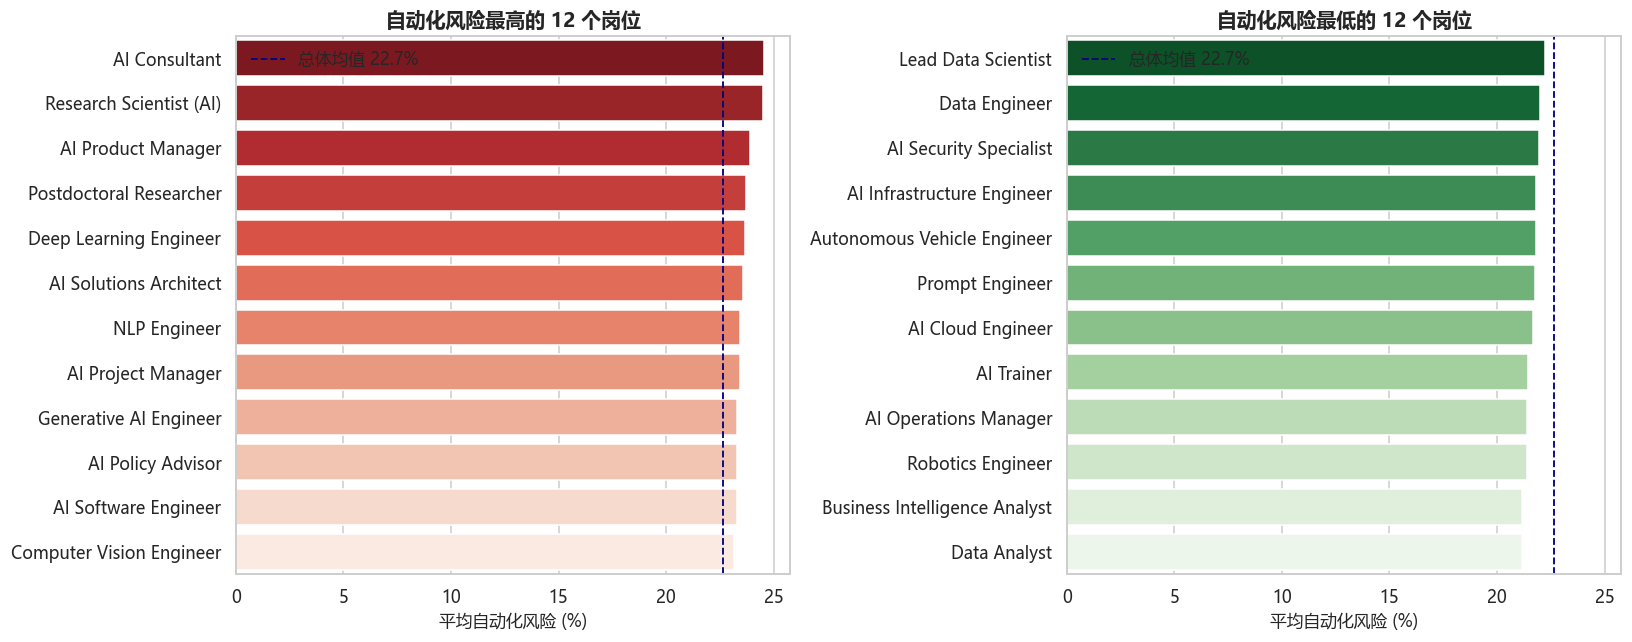

· 风险最高的岗位：AI Consultant（24.6%），前三名为 AI Consultant, Research Scientist (AI), AI Product Manager
· 风险最低的岗位：Data Analyst（21.2%），最低三名为 Data Analyst, Business Intelligence Analyst, Robotics Engineer
· 两端差距约 3 个百分点，整体风险水平可控（最高未超 25%）


In [8]:
role_risk = df.groupby("job_title")["automation_risk_pct"].agg(["mean", "count"]).query("count >= 100")["mean"]
high, low = role_risk.nlargest(12), role_risk.nsmallest(12)
overall = df["automation_risk_pct"].mean()

fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=True)

sns.barplot(x=high.values, y=high.index, hue=high.index, palette="Reds_r", legend=False, ax=axes[0])
axes[0].axvline(overall, color="navy", ls="--", lw=1.2, label=f"总体均值 {overall:.1f}%")
axes[0].set_title("自动化风险最高的 12 个岗位"); axes[0].set_xlabel("平均自动化风险 (%)"); axes[0].set_ylabel(""); axes[0].legend()

sns.barplot(x=low.sort_values(ascending=False).values, y=low.sort_values(ascending=False).index,
            hue=low.sort_values(ascending=False).index, palette="Greens_r", legend=False, ax=axes[1])
axes[1].axvline(overall, color="navy", ls="--", lw=1.2, label=f"总体均值 {overall:.1f}%")
axes[1].set_title("自动化风险最低的 12 个岗位"); axes[1].set_xlabel("平均自动化风险 (%)"); axes[1].set_ylabel(""); axes[1].legend()

plt.tight_layout(); plt.show()

insights(
    f"风险最高的岗位：{high.index[0]}（{high.iloc[0]:.1f}%），前三名为 {', '.join(high.index[:3])}",
    f"风险最低的岗位：{low.idxmin()}（{low.min():.1f}%），最低三名为 {', '.join(low.sort_values().index[:3])}",
    f"两端差距约 {high.iloc[0] - low.min():.0f} 个百分点，整体风险水平可控（最高未超 {role_risk.max():.0f}%）",
)

## 8. AI maturity by industry —— 行业 AI 成熟度

**管道**：`groupby(industry).agg( 成熟度均值, 薪资中位数, 岗位数 )` -> `sort_values` 排序后双图呈现。

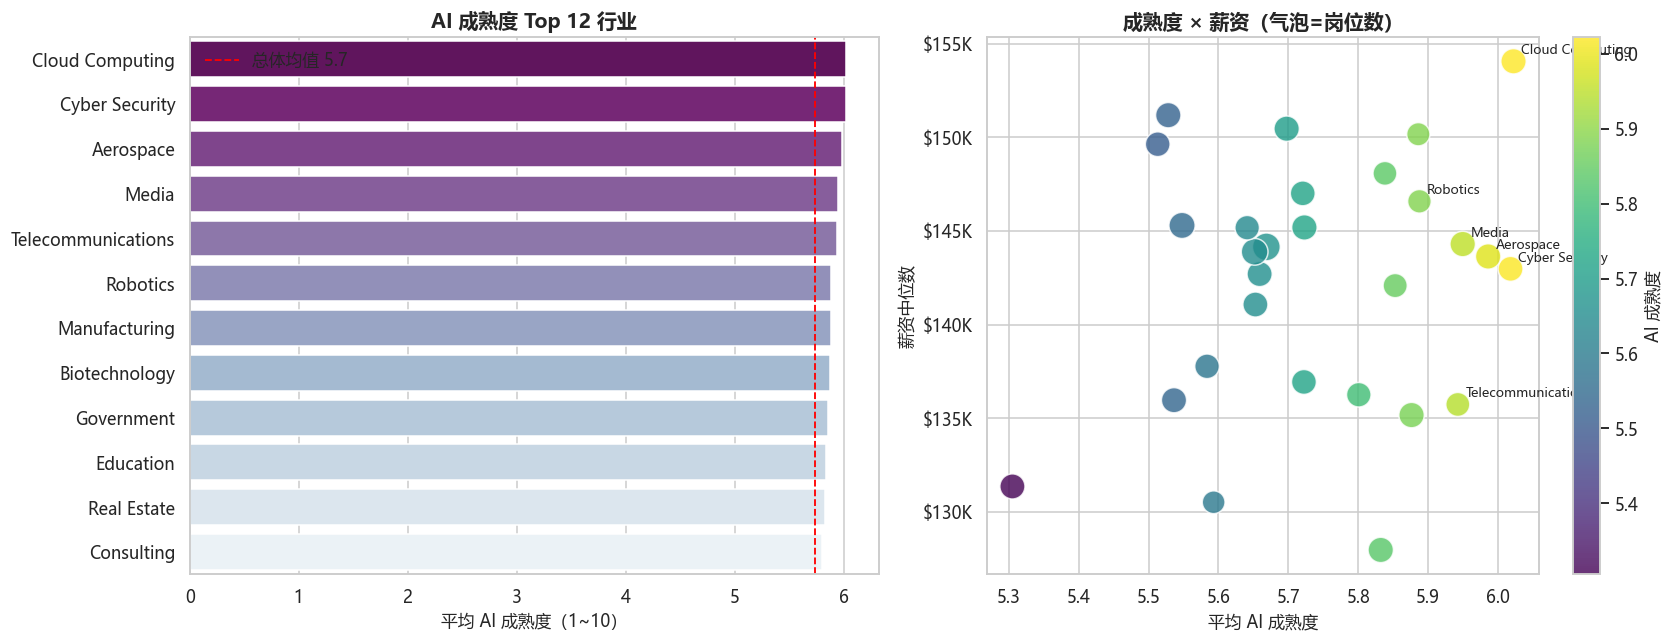

· AI 成熟度最高行业：Cloud Computing（6.02/10）
· 行业成熟度与薪资中位数相关性 r=0.19，成熟度高的行业并未显著支付更高薪资
· 成熟度整体围绕均值 5.7 波动，行业间数字鸿沟有限


In [9]:
maturity = (
    df.groupby("industry")
      .agg(ai_maturity=("ai_maturity", "mean"),
           median_salary=("salary_usd", "median"),
           jobs=("job_id", "count"))
      .sort_values("ai_maturity", ascending=False)
)

fig, axes = plt.subplots(1, 2, figsize=(15.5, 6))

top_mat = maturity.head(12)
sns.barplot(x=top_mat["ai_maturity"], y=top_mat.index, hue=top_mat.index,
            palette="BuPu_r", legend=False, ax=axes[0])
axes[0].axvline(df["ai_maturity"].mean(), color="red", ls="--", lw=1.2,
                label=f"总体均值 {df['ai_maturity'].mean():.1f}")
axes[0].set_title("AI 成熟度 Top 12 行业"); axes[0].set_xlabel("平均 AI 成熟度（1~10）"); axes[0].set_ylabel(""); axes[0].legend()

sc = axes[1].scatter(maturity["ai_maturity"], maturity["median_salary"],
                     s=maturity["jobs"] * 1.5, c=maturity["ai_maturity"], cmap="viridis",
                     alpha=0.8, edgecolor="white")
plt.colorbar(sc, ax=axes[1], label="AI 成熟度")
for name, row in maturity.head(6).iterrows():
    axes[1].annotate(name, (row["ai_maturity"], row["median_salary"]),
                     fontsize=8.5, xytext=(5, 5), textcoords="offset points")
axes[1].set_xlabel("平均 AI 成熟度"); axes[1].set_ylabel("薪资中位数")
axes[1].yaxis.set_major_formatter(fmt_usd)
axes[1].set_title("成熟度 × 薪资（气泡=岗位数）")

plt.tight_layout(); plt.show()

r_mat = maturity["ai_maturity"].corr(maturity["median_salary"])
insights(
    f"AI 成熟度最高行业：{maturity.index[0]}（{maturity['ai_maturity'].iloc[0]:.2f}/10）",
    f"行业成熟度与薪资中位数相关性 r={r_mat:.2f}，成熟度高的行业并未显著支付更高薪资",
    "成熟度整体围绕均值 5.7 波动，行业间数字鸿沟有限",
)

## 9. Career growth comparisons —— 职业发展路径对比

**管道**：取岗位数 Top 6 的职位 -> `groupby([job_title, experience_level])` 聚合薪资中位数 -> `unstack` 透视表。

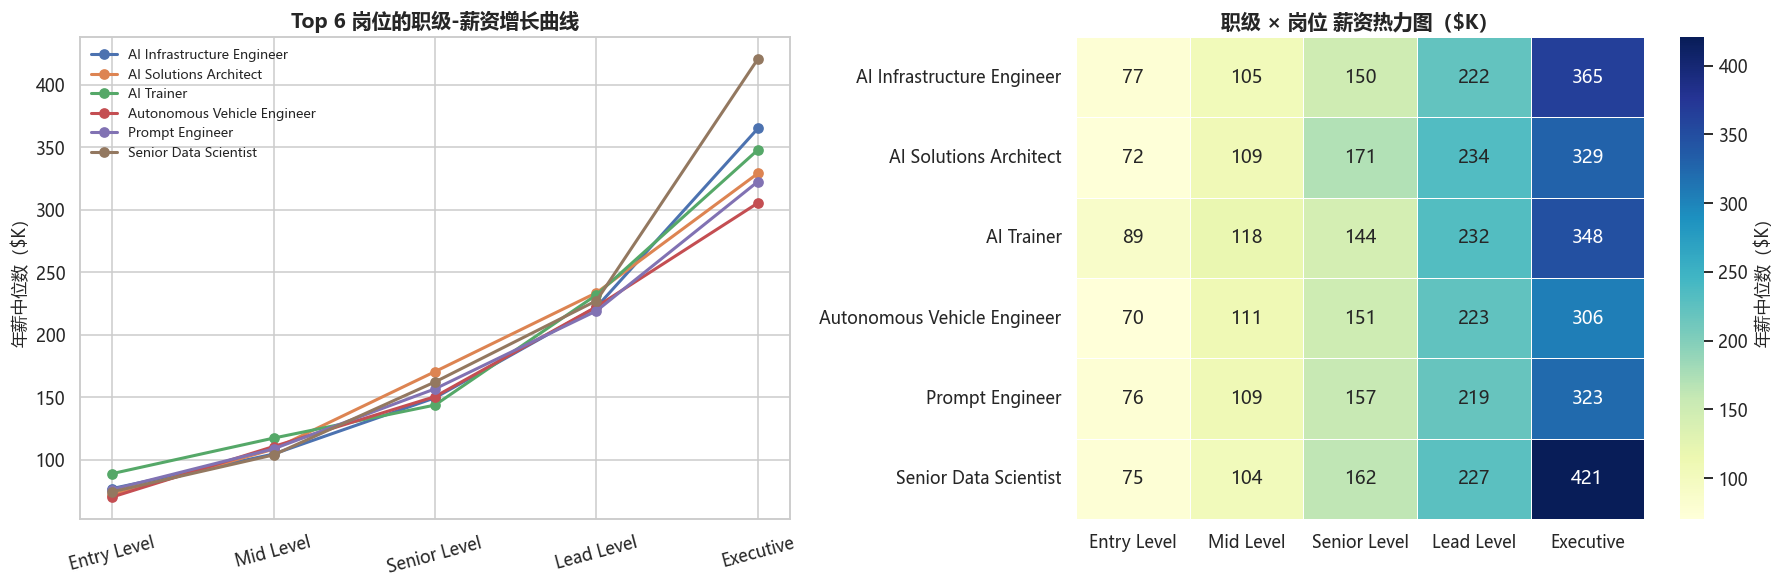

· 六类岗位薪资均随职级上升，Senior Data Scientist 的 Entry->Executive 涨幅最大（+$346K）
· 同一职级下不同岗位的薪资差异（横向）普遍大于职级带来的涨幅（纵向），选对赛道比熬资历更影响薪酬
· 单级跃迁涨幅最大：Senior Data Scientist 晋升至 Executive（+$193K）


In [10]:
top6 = df["job_title"].value_counts().head(6).index.tolist()
growth = (
    df[df["job_title"].isin(top6)]
      .groupby(["job_title", "experience_level"], observed=True)["salary_usd"].median()
      .unstack()[EXP_ORDER]
      .dropna(how="all")
)
growth_k = growth / 1000  # 以 $K 计，便于标注

fig, axes = plt.subplots(1, 2, figsize=(16.5, 5.5))

for title, row in growth_k.iterrows():
    axes[0].plot(EXP_ORDER, row.values, marker="o", lw=2, label=title)
axes[0].set_title("Top 6 岗位的职级-薪资增长曲线")
axes[0].set_ylabel("年薪中位数（$K）"); axes[0].tick_params(axis="x", rotation=15)
axes[0].legend(fontsize=8.5, loc="upper left")

sns.heatmap(growth_k, annot=True, fmt=".0f", cmap="YlGnBu", linewidths=0.5,
            cbar_kws={"label": "年薪中位数（$K）"}, ax=axes[1])
axes[1].set_title("职级 × 岗位 薪资热力图（$K）"); axes[1].set_xlabel(""); axes[1].set_ylabel("")

plt.tight_layout(); plt.show()

entry_exec = (growth["Executive"] - growth["Entry Level"]).dropna()
best_growth = entry_exec.idxmax()
steps = growth.diff(axis=1).dropna(axis=1, how="all").stack()
insights(
    f"六类岗位薪资均随职级上升，{best_growth} 的 Entry->Executive 涨幅最大（+{fmt_usd(entry_exec.max())}）",
    "同一职级下不同岗位的薪资差异（横向）普遍大于职级带来的涨幅（纵向），选对赛道比熬资历更影响薪酬",
    f"单级跃迁涨幅最大：{steps.idxmax()[0]} 晋升至 {steps.idxmax()[1]}（+{fmt_usd(steps.max())}）",
)